# Ejercicios con Matplotlib

`Manuel Avecilla`

---

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Ejercicio 1

Escribir un programa que pregunte al usuario por las ventas de un rango de años y muestre por pantalla un diagrama de líneas con la evolución de las ventas.

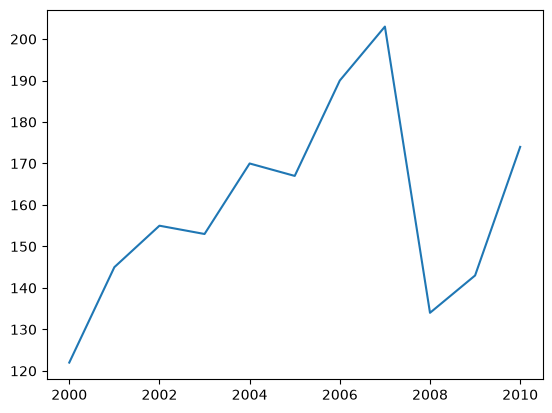

In [2]:
inicio = int(input('Introduce el año inicial: '))
fin = int(input('Introduce el año final: '))

ventas = {}

for i in range(inicio, fin+1):
    ventas[i] = float(input('Introduce las ventas del año ' + str(i) +': '))

fig, ax = plt.subplots()
ax.plot(ventas.keys(), ventas.values())
plt.show()



## Ejercicio 2

Escribir una función que reciba una diccionario con las notas de las asignaturas de un curso y una cadena con el nombre de un color y devuelva un diagrama de barras de las notas en el color dado.

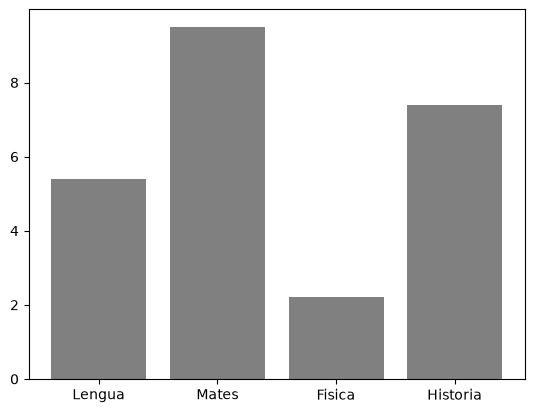

In [3]:
def diagrama_notas_barras(notas, color):

    fig, ax = plt.subplots()
    ax.bar(notas.keys(), notas.values(), color = color)
    return ax

notas = {'Lengua':5.4, 'Mates':9.5, 'Fisica':2.2, 'Historia': 7.4}
diagrama_notas_barras(notas, 'gray')
plt.show()

## Ejercicio 3

Escribir una función que reciba una serie de Pandas con las notas de los alumnos de un curso y devuelva un diagrama de cajas con las notas. El diagrama debe tener el título `"Distribución de notas"`.

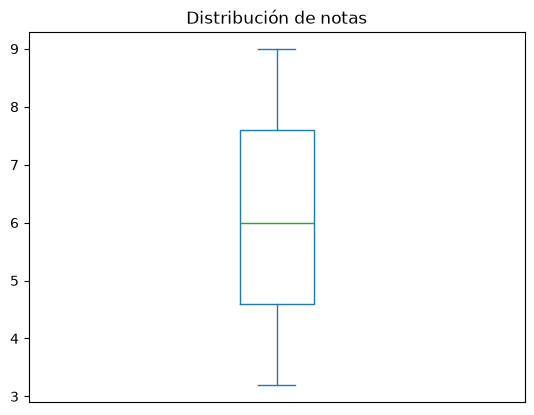

In [4]:
def diagrama_caja_notas(notas):

    fig, ax = plt.subplots()

    notas.plot(kind = 'box', ax = ax)

    plt.xticks([])

    plt.title('Distribución de notas')

    return ax

notas = [4, 8, 7.5, 6, 5.5, 5.2, 3.5, 7.7, 3.2, 9, 6.8]
s_notas = pd.Series(notas)
diagrama_caja_notas(s_notas)
plt.show()

## Ejercicio 4

El fichero `bancos.csv` contiene las cotizaciones de los principales bancos de España con las siguientes columnas:

- **`Empresa`**: nombre de la empresa.
- **`Apertura`**: precio de la acción a la apertura de bolsa.
- **`Máximo`**: precio máximo de la acción durante la jornada.
- **`Mínimo`**: precio mínimo de la acción durante la jornada.
- **`Cierre`**: precio de la acción al cierre de bolsa.
- **`Volumen`**: volumen al cierre de bolsa.

Construir una función que reciba el fichero `bancos.csv` y cree un diagrama de líneas con las series temporales de las cotizaciones de cierre de cada banco.

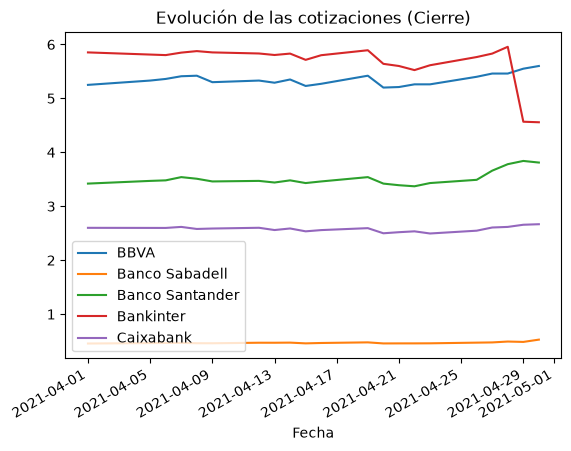

In [5]:
def evolucion_cotizacion(datos, variable):

    fig, ax = plt.subplots()

    datos.groupby('Empresa').plot(x = 'Fecha', y = variable, ax = ax)

    plt.title('Evolución de las cotizaciones (' + variable + ')')

    plt.legend(df_datos.groupby('Empresa').groups.keys())

    return ax

df_datos = pd.read_csv('bancos.csv')

df_datos["Fecha"] = pd.to_datetime(df_datos["Fecha"])

evolucion_cotizacion(df_datos, 'Cierre')

plt.show()


## Ejercicio 5

El fichero `titanic.csv` contiene información sobre los pasajeros del Titanic. Crear un DataFrame con Pandas y a partir de él generar los siguientes diagramas:
1. Diagrama de sectores con los fallecidos y supervivientes.

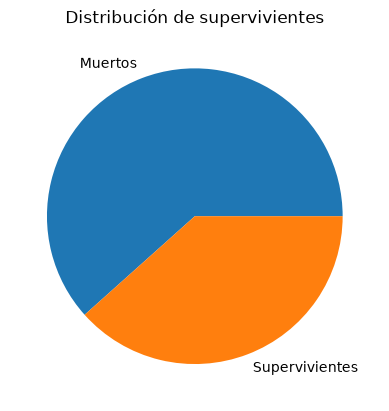

In [6]:
df_titanic = pd.read_csv('titanic.csv')

fig, ax = plt.subplots()

df_titanic.Survived.value_counts().plot(kind = "pie", labels = ["Muertos", "Supervivientes"], title = "Distribución de supervivientes")

plt.show()


2. Histograma con las edades.

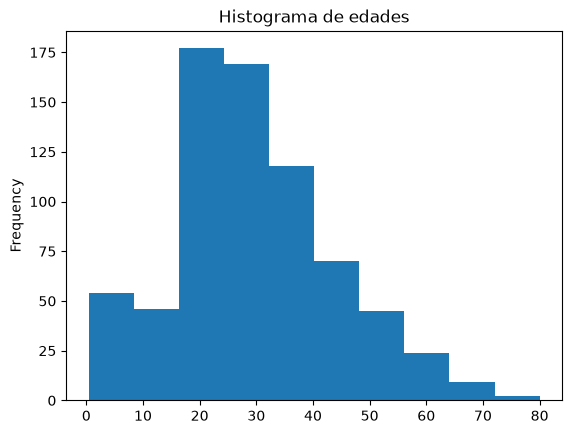

In [7]:
df_titanic.Age.plot(kind = "hist", title = "Histograma de edades")
plt.show()

3. Diagrama de barras con el número de personas en cada clase.

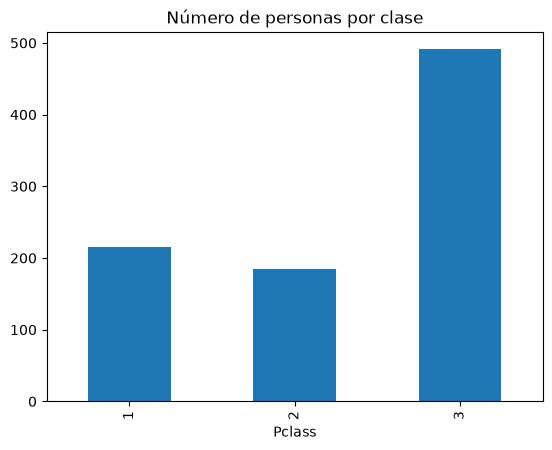

In [8]:
df_titanic.groupby("Pclass").size().plot(kind = "bar", title = "Número de personas por clase")
plt.show()

4. Diagrama de barras con el número de personas fallecidas y supervivientes en cada clase.

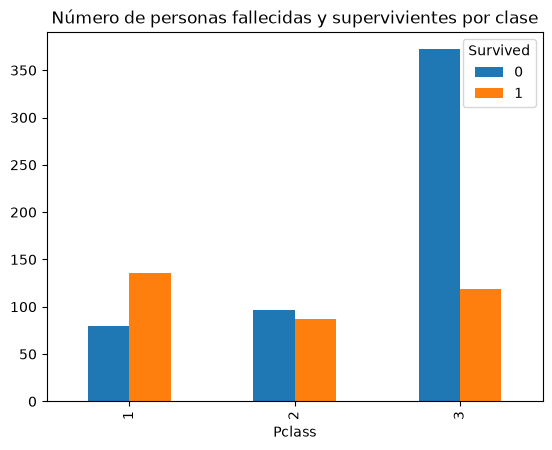

In [9]:
df_titanic.groupby(["Pclass", "Survived"]).size().unstack().plot(kind = "bar", title = "Número de personas fallecidas y supervivientes por clase")
plt.show()

5. Diagrama de barras con el número de personas fallecidas y supervivientes acumuladas en cada clase.

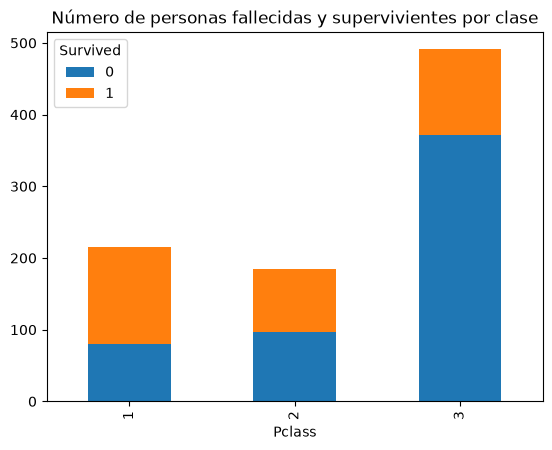

In [10]:
df_titanic.groupby(["Pclass", "Survived"]).size().unstack().plot(kind = "bar", stacked = True, title = "Número de personas fallecidas y supervivientes por clase")
plt.show()

---

### Conjunto de datos `tips` (Ejercicios 6–11)

Para realizar los siguientes ejercicios, usaremos principalmente el conjunto de datos `tips` de Seaborn. El código para cargar los datos es:

In [11]:
import seaborn as sns

# Cargar el conjunto de datos 'tips' de Seaborn
df = sns.load_dataset('tips')

df.sample(4)

,total_bill,tip,sex,smoker,day,time,size
235,10.07,1.25,Male,No,Sat,Dinner,2
15,21.58,3.92,Male,No,Sun,Dinner,2
10,10.27,1.71,Male,No,Sun,Dinner,2
227,20.45,3.00,Male,No,Sat,Dinner,4


## Ejercicio 6

Usando el dataset `tips` de Seaborn, crea una figura con 2 filas y 3 columnas en la que sitúes las siguientes gráficas:

**Requisitos de personalización:**
- Añade títulos y etiquetas a los ejes en cada subgráfico.
- Ajusta el espacio entre los subgráficos para que no se solapen.

1. Un gráfico de barras que muestre el total de la cuenta (`total_bill`) por día (`day`).
2. Un gráfico de líneas que muestre la relación entre el total de la cuenta (`total_bill`) y la propina (`tip`). Muestra también con una línea la propina media.
3. Un gráfico de dispersión entre el total de la cuenta (`total_bill`) y la propina (`tip`).
4. Un gráfico circular que muestre la distribución del total de la cuenta por sexo (`sex`).
5. Un histograma para la distribución del total de la cuenta (`total_bill`).
6. Un gráfico de caja y bigotes con los valores de las propinas (`tip`) en función del día de la semana (`day`).

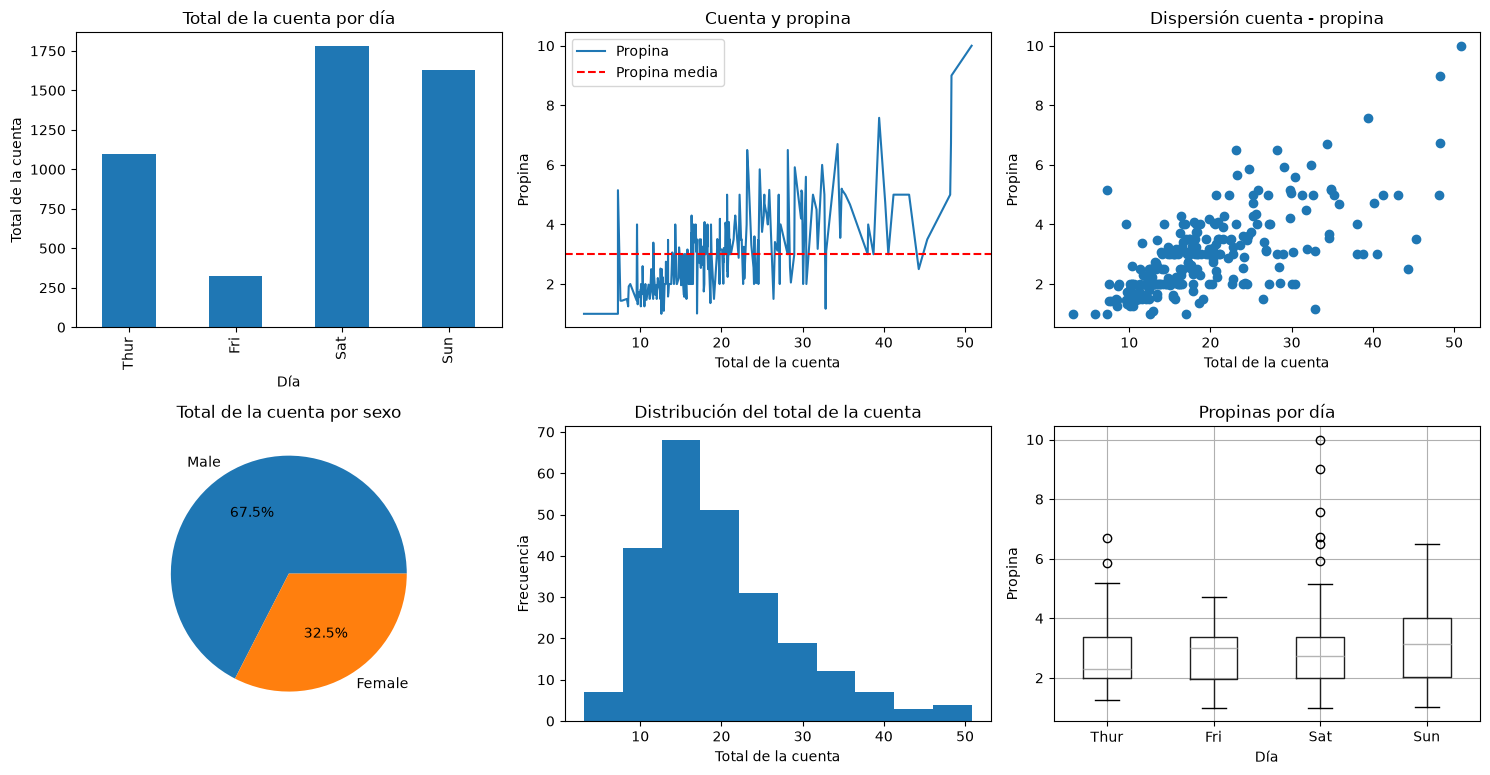

In [18]:
fig, axes = plt.subplots(2, 3, figsize = (15, 8))

df.groupby('day', observed = True)['total_bill'].sum().plot(kind = 'bar', ax = axes[0, 0])

axes[0, 0].set_title('Total de la cuenta por día')
axes[0, 0].set_xlabel('Día')
axes[0, 0].set_ylabel('Total de la cuenta')

df_ordenado = df.sort_values('total_bill')

axes[0, 1].plot(df_ordenado.total_bill, df_ordenado.tip, label = 'Propina')
axes[0, 1].axhline(df.tip.mean(), color = 'red', linestyle = '--', label = 'Propina media')

axes[0, 1].set_title('Cuenta y propina')
axes[0, 1].set_xlabel('Total de la cuenta')
axes[0, 1].set_ylabel('Propina')
axes[0, 1].legend()

axes[0, 2].scatter(df.total_bill, df.tip)

axes[0, 2].set_title('Dispersión cuenta - propina')
axes[0, 2].set_xlabel('Total de la cuenta')
axes[0, 2].set_ylabel('Propina')

df.groupby('sex', observed = True)['total_bill'].sum().plot(kind = 'pie', ax = axes[1, 0], autopct = '%1.1f%%')

axes[1, 0].set_title('Total de la cuenta por sexo')
axes[1, 0].set_ylabel('')

axes[1, 1].hist(df.total_bill)

axes[1, 1].set_title('Distribución del total de la cuenta')
axes[1, 1].set_xlabel('Total de la cuenta')
axes[1, 1].set_ylabel('Frecuencia')

df.boxplot(column = 'tip', by = 'day', ax = axes[1, 2])

axes[1, 2].set_title('Propinas por día')
axes[1, 2].set_xlabel('Día')
axes[1, 2].set_ylabel('Propina')

fig.suptitle('')
plt.tight_layout()
plt.show()

## Ejercicio 7

Usando el dataset `tips` de Seaborn, crea un gráfico de barras apiladas para mostrar cómo se distribuyen las propinas (`tip`) por día (`day`) y por sexo (`sex`).

**Requisitos de personalización:**
- Añade un título y etiquetas a los ejes.
- Ajusta los colores de las barras.

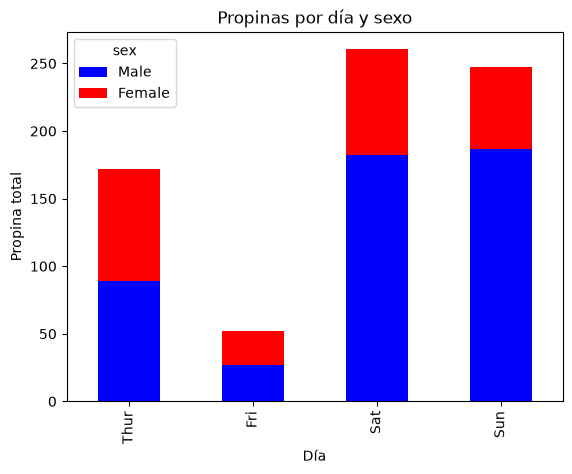

In [19]:
df.groupby(['day', 'sex'], observed = True)['tip'].sum().unstack().plot(kind = 'bar', stacked = True, color = ['blue', 'red'])

plt.title('Propinas por día y sexo')
plt.xlabel('Día')
plt.ylabel('Propina total')
plt.show()

## Ejercicio 8

Usando el dataset `tips` de Seaborn, crea un gráfico de líneas en el que se representen dos series:

- La relación entre `total_bill` y `tip`.
- La relación entre `total_bill` y el tamaño de la mesa (`size`).

**Requisitos de personalización:**
- Añade una leyenda que identifique las dos series.
- Añade un título y etiquetas a los ejes.

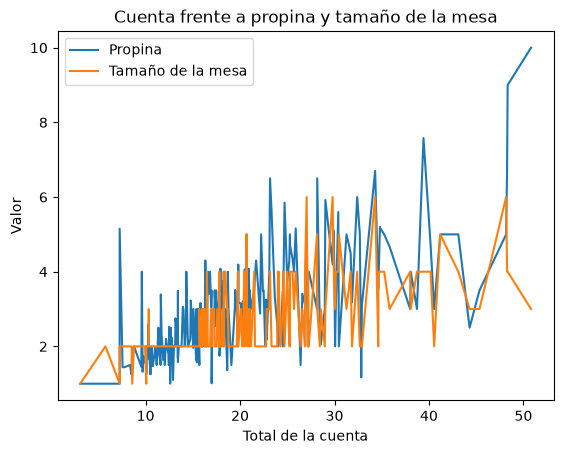

In [20]:
df_ordenado = df.sort_values('total_bill')

fig, ax = plt.subplots()

ax.plot(df_ordenado.total_bill, df_ordenado.tip, label = 'Propina')
ax.plot(df_ordenado.total_bill, df_ordenado['size'], label = 'Tamaño de la mesa')

ax.set_title('Cuenta frente a propina y tamaño de la mesa')
ax.set_xlabel('Total de la cuenta')
ax.set_ylabel('Valor')
ax.legend()

plt.show()

## Ejercicio 9

Usando el dataset `tips` de Seaborn, crea un gráfico de dispersión entre `total_bill` y `tip`.

Asigna colores diferentes a los puntos del gráfico según el género (`sex`) del cliente, utilizando `color='blue'` para los hombres y `color='red'` para las mujeres.

**Requisitos de personalización:**
- Añade un título, etiquetas a los ejes y una leyenda.

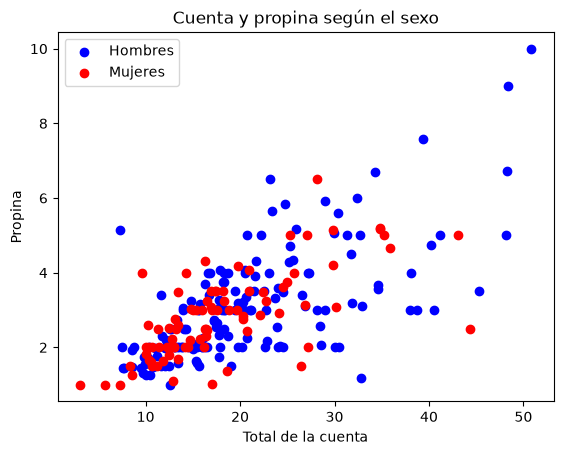

In [21]:
hombres = df[df.sex == 'Male']
mujeres = df[df.sex == 'Female']

fig, ax = plt.subplots()

ax.scatter(hombres.total_bill, hombres.tip, color = 'blue', label = 'Hombres')
ax.scatter(mujeres.total_bill, mujeres.tip, color = 'red', label = 'Mujeres')

ax.set_title('Cuenta y propina según el sexo')
ax.set_xlabel('Total de la cuenta')
ax.set_ylabel('Propina')
ax.legend()

plt.show()

## Ejercicio 10

Usando el dataset `tips` de Seaborn, crea una figura con subgráficos que contengan diferentes tipos de gráficos:

1. **Primer subgráfico:** crea un gráfico de barras que muestre la relación entre `day` y `total_bill`.
2. **Segundo subgráfico:** crea un gráfico circular que muestre la distribución de `total_bill` entre los géneros (`sex`).

**Requisitos de personalización:**
- Personaliza ambos gráficos con títulos, etiquetas en los ejes y ajuste del espacio entre los gráficos.

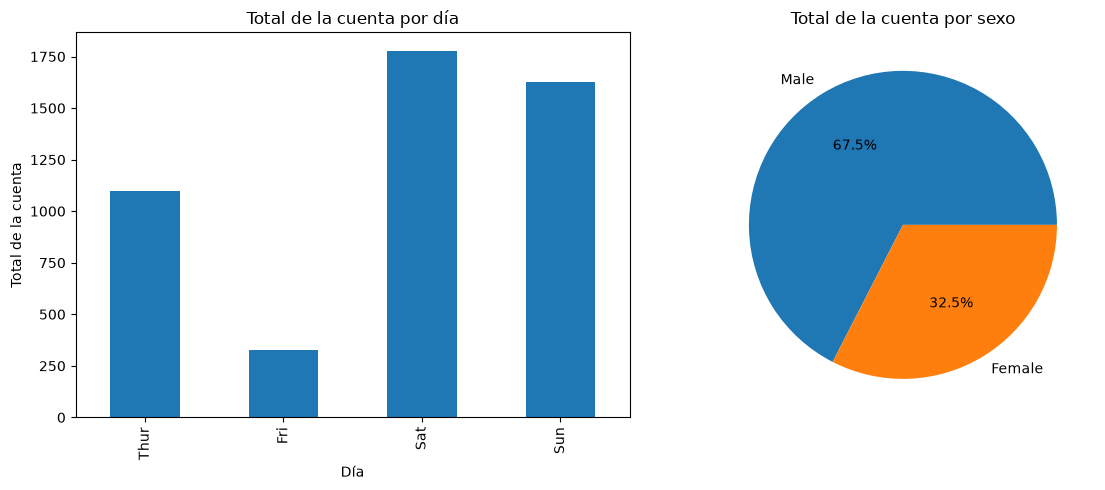

In [22]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5))

df.groupby('day', observed = True)['total_bill'].sum().plot(kind = 'bar', ax = axes[0])

axes[0].set_title('Total de la cuenta por día')
axes[0].set_xlabel('Día')
axes[0].set_ylabel('Total de la cuenta')

df.groupby('sex', observed = True)['total_bill'].sum().plot(kind = 'pie', ax = axes[1], autopct = '%1.1f%%')

axes[1].set_title('Total de la cuenta por sexo')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## Ejercicio 11

Usando el dataset `tips` de Seaborn, crea un gráfico de dispersión que muestre la relación entre `total_bill` y `tip`.

- Ajusta una línea de tendencia (regresión lineal) a los datos utilizando `scipy.stats.linregress()`.
- Muestra la línea de tendencia en el gráfico junto con los puntos de dispersión.

**Requisitos de personalización:**
- Personaliza el gráfico con un título, etiquetas a los ejes y una leyenda que indique la línea de tendencia.

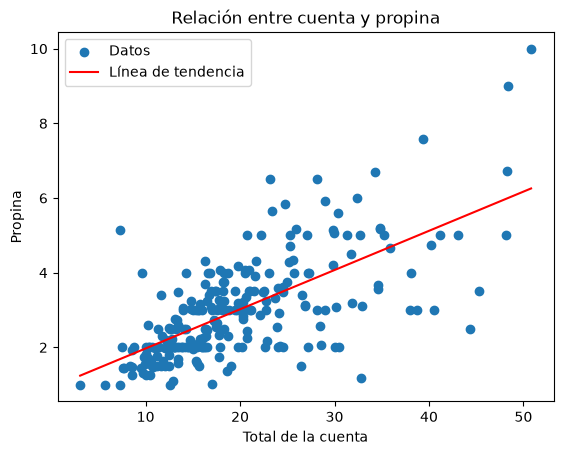

In [23]:
from scipy import stats

regresion = stats.linregress(df.total_bill, df.tip)

x = np.array([df.total_bill.min(), df.total_bill.max()])
y = regresion.slope * x + regresion.intercept

fig, ax = plt.subplots()

ax.scatter(df.total_bill, df.tip, label = 'Datos')
ax.plot(x, y, color = 'red', label = 'Línea de tendencia')

ax.set_title('Relación entre cuenta y propina')
ax.set_xlabel('Total de la cuenta')
ax.set_ylabel('Propina')
ax.legend()

plt.show()